# 쇼핑몰 단골 고객 분석

2025년 가상 쇼핑몰 구매 데이터를 전처리하고 RFM으로 고객 행동을 분류한다. 자체 생성한 합성 데이터는 과제 담당자 허용을 전제로 사용한다. 결과는 생성한 구매 패턴에 대한 분석이다.

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from src.generate_data import RAW_DATA_PATH
from src.pipeline import DataAnalyzer

%matplotlib inline
sns.set_theme(style="whitegrid")
analyzer = DataAnalyzer(RAW_DATA_PATH)
raw = analyzer.load_data()
figure_dir = root / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)


## 1. 데이터셋과 기초 탐색

한 행은 주문에 포함된 상품 한 종류다. 주문·고객·상품 ID는 가상 식별자다. 주문일, 상품명, 카테고리, 가격, 수량, 구매금액, JSON으로 인코딩한 8×8 회색조 배열을 함께 저장했다. 구매금액은 가격에 수량을 곱한 가상 원화 금액이다.

In [2]:
sample, overview = analyzer.explore()
display(sample.drop(columns="image_array"))
display(overview)
orders = raw["order_id"].nunique()
display(Markdown(
    f"고객 **{raw['customer_id'].nunique():,}명**, 상품 **{raw['product_id'].nunique():,}개**, "
    f"주문 **{orders:,}건**에 상품행이 **{len(raw):,}개**다. "
    f"주문당 평균 상품행은 {len(raw) / orders:.2f}개이므로 구매 빈도는 고유 주문 ID로 집계한다."
))
data_summary = pd.Series({
    "Transaction lines": len(raw), "Columns": raw.shape[1], "Customers": raw.customer_id.nunique(),
    "Products": raw.product_id.nunique(), "Unique orders": orders, "Categories": raw.category.nunique(),
})
display(data_summary.to_frame("count"))

<class 'pandas.DataFrame'>
RangeIndex: 7738 entries, 0 to 7737
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   customer_id   7738 non-null   str           
 1   order_id      7738 non-null   str           
 2   order_date    7738 non-null   datetime64[us]
 3   product_id    7738 non-null   str           
 4   product_name  7638 non-null   str           
 5   category      7738 non-null   str           
 6   price         7738 non-null   int64         
 7   quantity      7738 non-null   int64         
 8   amount        7738 non-null   int64         
 9   image_array   7738 non-null   str           
dtypes: datetime64[us](1), int64(3), str(6)
memory usage: 604.7 KB


,customer_id,order_id,order_date,product_id,product_name,category,price,quantity,amount
0,C0001,O000001,2025-02-28,P057,가상 가방 057,가방,53000,3,159000
1,C0001,O000001,2025-02-28,P043,가상 가방 043 기본형,가방,74000,2,148000
2,C0001,O000001,2025-02-28,P022,가상 신발 022 기본형,신발,42000,1,42000
3,C0001,O000002,2025-04-12,P046,가상 가방 046 기본형,가방,63000,3,189000
4,C0001,O000003,2025-07-03,P031,가상 신발 031 기본형,신발,65000,1,65000


,customer_id,order_id,order_date,product_id,product_name,category,price,quantity,amount,image_array
count,7738,7738,7738,7738,7638,7738,7738.000000,7738.000000,7.738000e+03,7738
unique,500,3877,NaN,100,100,5,NaN,NaN,NaN,100
top,C0446,O000001,NaN,P018,가상 의류 018,전자기기,NaN,NaN,NaN,"[[52,60,62,197,180,203,193,203],[45,25,62,207,..."
freq,43,3,NaN,169,165,2027,NaN,NaN,NaN,169
mean,NaN,NaN,2025-06-30 14:50:27.759111,NaN,NaN,NaN,97897.001809,2.133368,2.111093e+05,NaN
min,NaN,NaN,2025-01-01 00:00:00,NaN,NaN,NaN,6000.000000,1.000000,6.000000e+03,NaN
25%,NaN,NaN,2025-03-31 00:00:00,NaN,NaN,NaN,65000.000000,1.000000,9.000000e+04,NaN
50%,NaN,NaN,2025-06-24 00:00:00,NaN,NaN,NaN,80000.000000,2.000000,1.600000e+05,NaN
75%,NaN,NaN,2025-10-02 00:00:00,NaN,NaN,NaN,117000.000000,3.000000,2.440000e+05,NaN
max,NaN,NaN,2025-12-31 00:00:00,NaN,NaN,NaN,244000.000000,58.000000,1.303500e+07,NaN


고객 **500명**, 상품 **100개**, 주문 **3,877건**에 상품행이 **7,738개**다. 주문당 평균 상품행은 2.00개이므로 구매 빈도는 고유 주문 ID로 집계한다.

,count
Transaction lines,7738
Columns,10
Customers,500
Products,100
Unique orders,3877
Categories,5


## 2. 결측치 분석

상품 ID별로 관측된 상품명의 최빈값을 적용한다. 관측값이 없는 그룹에는 전체 최빈값을 사용한다.

In [3]:
missing_before = analyzer.missing_counts()
analyzer.handle_missing()
missing_after = analyzer.missing_counts()
display(missing_before.to_frame("before").assign(after=missing_after))
display(Markdown(
    f"상품명 결측은 **{missing_before['product_name']}행에서 {missing_after['product_name']}행**으로 "
    "줄었다. SKU의 기존 상품명을 복구해 텍스트 피처를 계산할 수 있다."
))
before = raw["product_name"].value_counts(dropna=False).rename("before")
after = analyzer.df["product_name"].value_counts(dropna=False).rename("after")
name_counts = pd.concat([before, after], axis=1).fillna(0).astype(int)
name_counts["change"] = name_counts["after"] - name_counts["before"]
display(name_counts.sort_values("change", ascending=False).head(10))

def name_distribution(frame):
    rows = []
    for category, group in frame.groupby("category"):
        proportions = group["product_name"].value_counts(normalize=True)
        rows.append({
            "category": category, "missing": group["product_name"].isna().sum(),
            "distinct_names": len(proportions), "top_share": proportions.max(),
            "entropy_bits": -(proportions * np.log2(proportions)).sum(),
        })
    return pd.DataFrame(rows).set_index("category")

display(pd.concat({
    "before": name_distribution(raw), "after": name_distribution(analyzer.df),
}, axis=1).round(3))
restored = name_counts["change"].dropna().loc[lambda values: values.gt(0)]
display(Markdown(
    f"복원된 거래행은 **{restored.sum()}개**이며 이름 **{len(restored)}종**의 빈도가 증가했다. "
    "범주별 최빈 이름 비중과 엔트로피는 이름이 관측된 거래행을 분모로 사용한다."
))

,before,after
customer_id,0,0
order_id,0,0
order_date,0,0
product_id,0,0
product_name,100,0
category,0,0
price,0,0
quantity,0,0
amount,0,0
image_array,0,0


상품명 결측은 **100행에서 0행**으로 줄었다. SKU의 기존 상품명을 복구해 텍스트 피처를 계산할 수 있다.

,before,after,change
product_name,,,
가상 의류 018,169,169,0
가상 의류 020 기본형,52,52,0
가상 가방 048,48,48,0
가상 생활용품 063,48,48,0
가상 생활용품 073 기본형,48,48,0
가상 생활용품 074 기본형,48,48,0
가상 생활용품 064 기본형,49,49,0
가상 신발 028 기본형,49,49,0
가상 가방 041 기본형,50,50,0


before                                         after                 \
         missing distinct_names top_share entropy_bits missing distinct_names   
category                                                                        
가방             0             20     0.086        4.160       0             20   
생활용품           0             20     0.096        4.074       0             20   
신발             0             20     0.086        4.199       0             20   
의류             0             20     0.127        3.961       0             20   
전자기기           0             20     0.066        4.277       0             20   

                                 
         top_share entropy_bits  
category                         
가방           0.086        4.160  
생활용품         0.096        4.074  
신발           0.086        4.199  
의류           0.127        3.961  
전자기기         0.066        4.277

복원된 거래행은 **0개**이며 이름 **0종**의 빈도가 증가했다. 범주별 최빈 이름 비중과 엔트로피는 이름이 관측된 거래행을 분모로 사용한다.

**대치 결과 해석.** 이 데이터의 상품 ID는 상품명에 대응하므로 SKU 최빈값은 알려진 이름을 복원하는 데 적합하다. 빈도표에서는 복원한 이름의 거래행 수가 증가한다. 관측 이름만을 분모로 정규화하면 범주별 최빈 비중과 엔트로피의 변화 방향은 결측의 위치에 따라 달라진다. 여러 이름이 같은 그룹에 속하는 실제 데이터에서 최빈값 대치를 반복하면 선택된 이름의 비중이 커지고 다양성이 낮아지거나, 그룹마다 다른 최빈값으로 대치해 그룹 차이가 과장될 수 있다. SKU가 잘못 연결되거나 그룹이 전부 결측이면 다른 상품 이름이 대입될 수 있으므로 대치 전에 식별자 정합성을 점검한다.

## 3. 이상치 분석

수량의 Q1과 Q3에서 1.5×IQR만큼 확장한 경계 밖을 탐지한다. 시각적 비교용으로 수량 보정 컬럼을 만들며, 합성 과정에서 의도한 대량 주문은 관측 거래금액과 RFM 집계에 포함한다.

In [4]:
lower, upper = analyzer.iqr_bounds("quantity")
outliers = analyzer.detect_outliers()
clipped = analyzer.add_clipped_feature()
display(Markdown(
    f"수량 경계는 **{lower:g}~{upper:g}개**, 이상치는 **{len(outliers)}행**이다. "
    f"최댓값은 관측 수량 {raw['quantity'].max()}개, 비교용 보정 수량 {clipped.max():g}개로, "
    "대량 구매가 원본 분포의 꼬리를 늘린다."
))
quantity = raw["quantity"]
z = (quantity - quantity.mean()) / quantity.std(ddof=0)
z_mask = z.abs().gt(3)
iqr_mask = quantity.lt(lower) | quantity.gt(upper)
comparison = pd.Series({
    "IQR": iqr_mask.sum(), "Absolute Z-score > 3": z_mask.sum(),
    "Both": (iqr_mask & z_mask).sum(), "IQR only": (iqr_mask & ~z_mask).sum(),
    "Z-score only": (z_mask & ~iqr_mask).sum(),
})
display(comparison.to_frame("rows"))
display(pd.Series({
    "IQR lower": lower, "IQR upper": upper, "IQR percentage": iqr_mask.mean() * 100,
    "Observed max": quantity.max(), "Clipped max": clipped.max(),
    "Z-score lower": quantity.mean() - 3 * quantity.std(ddof=0),
    "Z-score upper": quantity.mean() + 3 * quantity.std(ddof=0),
    "Sample skewness": quantity.skew(),
}).round(3).to_frame("value"))
display(Markdown(
    f"표본 왜도는 **{quantity.skew():.2f}**로 오른쪽 꼬리가 길다. "
    f"IQR은 {iqr_mask.sum()}행({iqr_mask.mean():.2%}), Z-score는 {z_mask.sum()}행을 표시했고 "
    f"공통 탐지 건수는 {(iqr_mask & z_mask).sum()}행이다. "
    "탐지 규칙의 결과는 이 자료의 수량 간격과 대량 주문 크기에 영향을 받는다."
))

수량 경계는 **-2~6개**, 이상치는 **24행**이다. 최댓값은 관측 수량 58개, 비교용 보정 수량 6개로, 대량 구매가 원본 분포의 꼬리를 늘린다.

,rows
IQR,24
Absolute Z-score > 3,24
Both,24
IQR only,0
Z-score only,0


,value
IQR lower,-2.000
IQR upper,6.000
IQR percentage,0.310
Observed max,58.000
Clipped max,6.000
Z-score lower,-5.288
Z-score upper,9.555
Sample skewness,16.212


표본 왜도는 **16.21**로 오른쪽 꼬리가 길다. IQR은 24행(0.31%), Z-score는 24행을 표시했고 공통 탐지 건수는 24행이다. 탐지 규칙의 결과는 이 자료의 수량 간격과 대량 주문 크기에 영향을 받는다.

**IQR과 Z-score의 해석.** IQR은 Q3−Q1이고 판정 경계는 Q1−1.5×IQR과 Q3+1.5×IQR이다. Z-score는 (수량−평균)/모집단 표준편차이며 절댓값이 3을 초과하는 행을 비교 대상으로 삼는다. 평균과 표준편차는 꼬리의 큰 값에도 영향을 받으며, 정규분포의 3σ 확률을 비대칭·이산 수량에 적용할 근거는 없다. IQR은 중앙 50%에 의존해 극단값의 영향이 작지만, 비대칭의 긴 꼬리에서 정상 거래를 표시하거나 동점이 많아 IQR이 0이면 작은 차이도 표시할 수 있다. 이번 대량 구매는 생성 과정에서 유효 거래로 설정했으므로 관측 금액을 매출과 RFM에 사용한다.

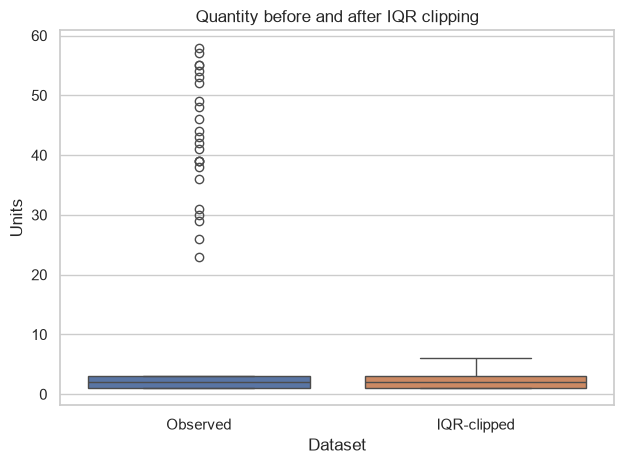

수량 24행을 비교용 컬럼에서 보정한 뒤 최대 수량이 **58개에서 6개**가 됐다. 중앙 구간과 대량 주문의 간격을 비교할 수 있다.

In [5]:
fig, ax = plt.subplots()
quantity_comparison = analyzer.df[["quantity", "quantity_clipped"]].rename(
    columns={"quantity": "Observed", "quantity_clipped": "IQR-clipped"}
)
sns.boxplot(data=quantity_comparison, ax=ax)
ax.set(title="Quantity before and after IQR clipping", xlabel="Dataset", ylabel="Units")
fig.tight_layout()
fig.savefig(figure_dir / "02_outlier_boxplot.png", dpi=150)
plt.show()
display(Markdown(
    f"수량 {iqr_mask.sum()}행을 비교용 컬럼에서 보정한 뒤 최대 수량이 "
    f"**{quantity.max()}개에서 {clipped.max():g}개**가 됐다. 중앙 구간과 대량 주문의 간격을 비교할 수 있다."
))

## 4. 텍스트·이미지 피처

상품명 단어를 세고, 고유 JSON 배열을 복원해 픽셀 축을 따라 NumPy 평균과 모집단 표준편차를 계산한다. 해당 피처를 SKU가 반복 등장하는 거래행에도 연결한다.

In [6]:
analyzer.add_text_features()
analyzer.add_image_features()
features = analyzer.df[["name_word_count", "image_mean", "image_std"]]
display(features.describe().round(2))
display(Markdown(
    f"상품명은 **{features.name_word_count.min()}~{features.name_word_count.max()}단어**, "
    f"이미지 평균 밝기는 **{features.image_mean.min():.1f}~{features.image_mean.max():.1f}**다. "
    "픽셀 평균과 표준편차로 합성 이미지의 밝기와 대비 차이를 수치화할 수 있다."
))
processed = root / "data" / "processed"
analyzer.save_processed(processed / "ecommerce_clean.csv")
display(analyzer.df[["product_id", "product_name", "name_word_count", "image_mean", "image_std"]]
        .drop_duplicates("product_id").head(8).round(2))

,name_word_count,image_mean,image_std
count,7738.00,7738.00,7738.00
mean,3.66,121.86,72.27
std,0.47,11.65,1.76
min,3.00,105.98,68.61
25%,3.00,110.20,71.12
50%,4.00,118.28,72.35
75%,4.00,134.64,73.84
max,4.00,138.59,75.91


상품명은 **3~4단어**, 이미지 평균 밝기는 **106.0~138.6**다. 픽셀 평균과 표준편차로 합성 이미지의 밝기와 대비 차이를 수치화할 수 있다.

,product_id,product_name,name_word_count,image_mean,image_std
0,P057,가상 가방 057,3,107.42,72.53
1,P043,가상 가방 043 기본형,4,110.98,75.12
2,P022,가상 신발 022 기본형,4,135.86,70.02
3,P046,가상 가방 046 기본형,4,107.52,72.85
4,P031,가상 신발 031 기본형,4,138.59,71.60
5,P033,가상 신발 033,3,134.86,70.33
6,P050,가상 가방 050 기본형,4,107.70,73.15
7,P036,가상 신발 036,3,133.66,72.58


## 5. 기술통계와 상관관계

기술통계와 상관계수의 관측 단위는 상품 거래행이다. 가격 히스토그램은 고유 상품을 한 번씩 집계한다.

In [7]:
stats = analyzer.descriptive_statistics()
correlations = analyzer.correlations()
display(stats.round(2))
display(Markdown(
    f"거래행당 구매금액 평균은 **{stats.loc['amount', 'mean']:,.0f}원**, "
    f"중앙값은 **{stats.loc['amount', 'median']:,.0f}원**이다. "
    "고액 거래행이 평균을 끌어올리므로 대표 금액을 설명할 때 중앙값을 함께 본다."
))
display(Markdown(
    f"가격과 수량의 피어슨 상관은 **{correlations.loc['price', 'quantity']:.3f}**으로 "
    "이 데이터에서 선형 관계가 약하다. "
    f"수량과 금액의 상관은 **{correlations.loc['quantity', 'amount']:.3f}**이다. "
    "구매금액을 가격×수량으로 정의했으므로 두 변수의 상관에는 계산식의 영향이 포함된다."
))
display(Markdown(
    f"단가의 가운데 50%는 **{stats.loc['price', '25%']:,.0f}~{stats.loc['price', '75%']:,.0f}원**, "
    f"표준편차는 **{stats.loc['price', 'std']:,.0f}원**이다. 거래 단가의 일반적인 범위는 사분위수로 요약한다. "
    f"구매 수량의 사분위수는 **{stats.loc['quantity', '25%']:g}~{stats.loc['quantity', '75%']:g}개**, "
    f"표준편차는 **{stats.loc['quantity', 'std']:.2f}개**여서 대량 구매를 별도로 살펴볼 필요가 있다. "
    f"금액의 가운데 50%는 **{stats.loc['amount', '25%']:,.0f}~{stats.loc['amount', '75%']:,.0f}원**, "
    f"표준편차는 **{stats.loc['amount', 'std']:,.0f}원**이다. 매출 기여를 해석할 때 대량 거래를 구분해 본다."
))

,count,mean,std,min,25%,median,75%,max
price,7738.0,97897.00,56445.19,6000.0,65000.0,80000.0,117000.0,244000.0
quantity,7738.0,2.13,2.47,1.0,1.0,2.0,3.0,58.0
amount,7738.0,211109.33,351833.43,6000.0,90000.0,160000.0,244000.0,13035000.0


거래행당 구매금액 평균은 **211,109원**, 중앙값은 **160,000원**이다. 고액 거래행이 평균을 끌어올리므로 대표 금액을 설명할 때 중앙값을 함께 본다.

가격과 수량의 피어슨 상관은 **0.016**으로 이 데이터에서 선형 관계가 약하다. 수량과 금액의 상관은 **0.816**이다. 구매금액을 가격×수량으로 정의했으므로 두 변수의 상관에는 계산식의 영향이 포함된다.

단가의 가운데 50%는 **65,000~117,000원**, 표준편차는 **56,445원**이다. 거래 단가의 일반적인 범위는 사분위수로 요약한다. 구매 수량의 사분위수는 **1~3개**, 표준편차는 **2.47개**여서 대량 구매를 별도로 살펴볼 필요가 있다. 금액의 가운데 50%는 **90,000~244,000원**, 표준편차는 **351,833원**이다. 매출 기여를 해석할 때 대량 거래를 구분해 본다.

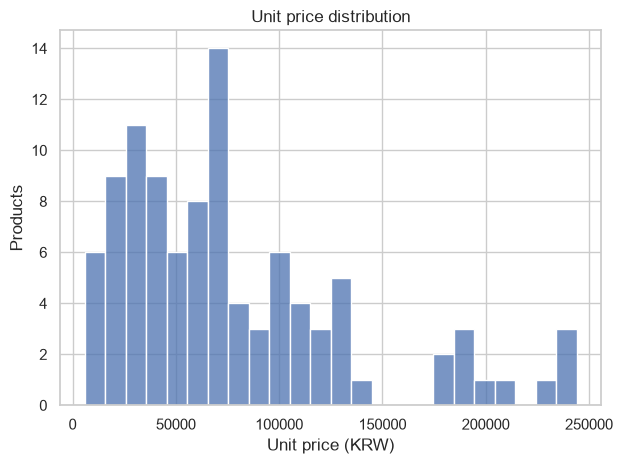

고유 상품 **100개**의 단가 중앙값은 **67,000원**이다. 상품당 한 번 집계해 인기 상품의 반복 주문이 가격 분포에 미치는 영향을 제거했다.

In [8]:
fig, ax = plt.subplots()
sns.histplot(data=analyzer.df.drop_duplicates("product_id"), x="price", bins=24, ax=ax)
ax.set(title="Unit price distribution", xlabel="Unit price (KRW)", ylabel="Products")
fig.tight_layout()
fig.savefig(figure_dir / "01_price_histogram.png", dpi=150)
plt.show()
product_prices = analyzer.df.drop_duplicates("product_id")["price"]
display(Markdown(
    f"고유 상품 **{len(product_prices)}개**의 단가 중앙값은 **{product_prices.median():,.0f}원**이다. "
    "상품당 한 번 집계해 인기 상품의 반복 주문이 가격 분포에 미치는 영향을 제거했다."
))

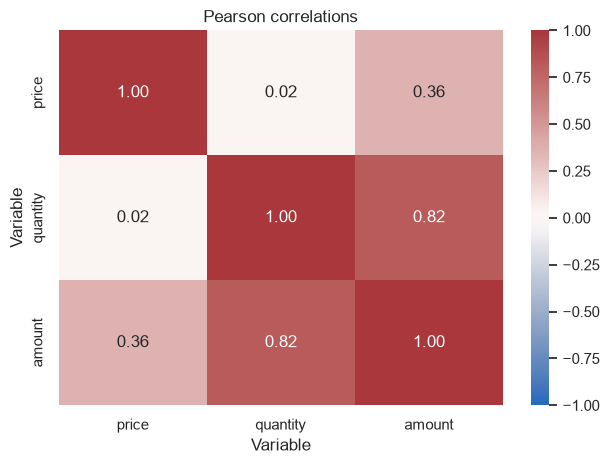

절댓값이 가장 큰 비대각 상관은 수량–금액의 **0.816**이다. 금액에 수량이 곱해지므로 이를 구매 행동의 인과관계로 해석하기 어렵다.

In [9]:
fig, ax = plt.subplots()
sns.heatmap(correlations, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag", ax=ax)
ax.set(title="Pearson correlations", xlabel="Variable", ylabel="Variable")
fig.tight_layout()
fig.savefig(figure_dir / "04_correlation_heatmap.png", dpi=150)
plt.show()
display(Markdown(
    f"절댓값이 가장 큰 비대각 상관은 수량–금액의 **{correlations.loc['quantity', 'amount']:.3f}**이다. "
    "금액에 수량이 곱해지므로 이를 구매 행동의 인과관계로 해석하기 어렵다."
))

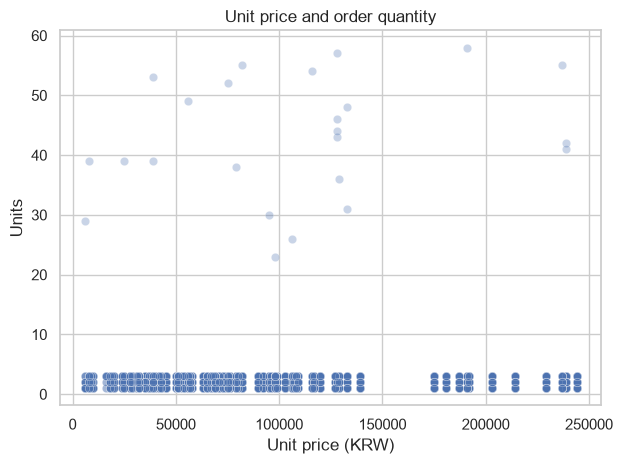

가격–수량의 상관은 **0.016**이며 일반 구간의 75% 경계는 **3개**다. 반복되는 정수 수량과 상단의 대량 주문을 함께 볼 수 있다.

In [10]:
fig, ax = plt.subplots()
sns.scatterplot(data=analyzer.df, x="price", y="quantity", alpha=0.3, ax=ax)
ax.set(title="Unit price and order quantity", xlabel="Unit price (KRW)", ylabel="Units")
fig.tight_layout()
fig.savefig(figure_dir / "05_price_quantity_scatter.png", dpi=150)
plt.show()
display(Markdown(
    f"가격–수량의 상관은 **{correlations.loc['price', 'quantity']:.3f}**이며 "
    f"일반 구간의 75% 경계는 **{stats.loc['quantity', '75%']:g}개**다. 반복되는 정수 수량과 상단의 대량 주문을 함께 볼 수 있다."
))

## 6. 월별 매출

거래행의 관측 구매금액을 주문 월별로 합산한다.

In [11]:
monthly = analyzer.monthly_sales()
display(monthly.to_frame("sales"))
display(Markdown(
    f"최고 매출 월은 **{monthly.idxmax()} ({monthly.max():,}원)**, "
    f"최저는 **{monthly.idxmin()} ({monthly.min():,}원)**이다. "
    "월별 차이에는 합성 데이터에서 설정한 고객별 활동 기간이 반영되어 있다."
))

,sales
order_date,
2025-01,133381000
2025-02,141242000
2025-03,157646000
2025-04,133254000
2025-05,164048000
2025-06,129966000
2025-07,129705000
2025-08,140403000
2025-09,93290000


최고 매출 월은 **2025-12 (180,745,000원)**, 최저는 **2025-09 (93,290,000원)**이다. 월별 차이에는 합성 데이터에서 설정한 고객별 활동 기간이 반영되어 있다.

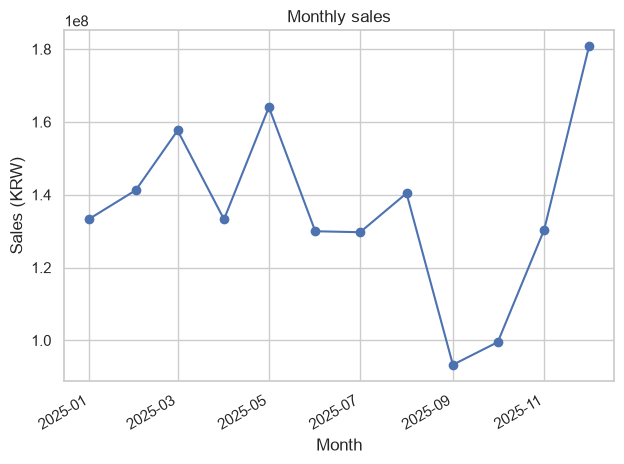

월별 최고 매출은 **2025-12의 180,745,000원**이다. 최저 월보다 **1.94배** 높으며 생성한 고객 활동 기간의 영향을 받는다.

In [12]:
fig, ax = plt.subplots()
ax.plot(monthly.index.to_timestamp(), monthly.to_numpy(), marker="o")
ax.set(title="Monthly sales", xlabel="Month", ylabel="Sales (KRW)")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(figure_dir / "06_monthly_sales.png", dpi=150)
plt.show()
display(Markdown(
    f"월별 최고 매출은 **{monthly.idxmax()}의 {monthly.max():,}원**이다. "
    f"최저 월보다 **{monthly.max() / monthly.min():.2f}배** 높으며 생성한 고객 활동 기간의 영향을 받는다."
))

## 7. RFM 세분화

마지막 거래일을 기준으로 최근 구매 후 경과일(R), 고유 주문 수(F), 총구매금액(M)을 계산한다. 각 지표는 평균 순위 백분율에 5를 곱한 뒤 올림한다. R은 짧을수록, F와 M은 클수록 높은 점수를 받는다.

배정 순서는 **Churned**(마지막 구매 후 90일 이상), **New**(관측기간 첫 구매 후 30일 이내이며 총 주문 2회 이하), **VIP**(총 주문 3회 이상이며 R·F·M 각각 4점 이상), **Loyal**(나머지)이다.

In [13]:
rfm = analyzer.calculate_rfm()
segments = analyzer.summarize_segments(rfm)
display(segments.round(2))
rfm.to_csv(processed / "customer_rfm.csv")
display(Markdown(
    f"VIP는 평균 **{segments.loc['VIP', 'average_frequency']:.2f}회** 구매했고, "
    f"Loyal의 평균은 **{segments.loc['Loyal', 'average_frequency']:.2f}회**였다. "
    "두 그룹에 서로 다른 혜택을 시험할 근거로 구매 빈도를 활용할 수 있다. "
    f"New의 평균 주문은 **{segments.loc['New', 'average_frequency']:.2f}회**라 두 번째 구매를 "
    "유도할 대상을 그룹 내에서 찾을 수 있다. "
    f"Churned의 마지막 구매 후 평균 **{segments.loc['Churned', 'average_recency']:.2f}일**이 "
    "지났으므로 재구매 유도 효과를 별도로 측정할 수 있다."
))
display(Markdown(
    f"VIP의 구매금액 비중은 **{segments.loc['VIP', 'total_monetary'] / rfm.monetary.sum():.1%}**이며, "
    f"New 중 단일 주문 고객은 **{(rfm.segment.eq('New') & rfm.frequency.eq(1)).sum()}명**이다. "
    "Loyal은 앞선 조건에 해당하지 않은 고객군으로 분류했다."
))

,customers,average_monetary,average_frequency,average_recency,total_monetary
segment,,,,,
VIP,89,7389022.47,14.64,9.38,657623000
Loyal,161,4284291.93,11.02,25.79,689771000
New,125,505400.00,1.45,11.10,63175000
Churned,125,1783960.00,4.94,159.35,222995000


VIP는 평균 **14.64회** 구매했고, Loyal의 평균은 **11.02회**였다. 두 그룹에 서로 다른 혜택을 시험할 근거로 구매 빈도를 활용할 수 있다. New의 평균 주문은 **1.45회**라 두 번째 구매를 유도할 대상을 그룹 내에서 찾을 수 있다. Churned의 마지막 구매 후 평균 **159.35일**이 지났으므로 재구매 유도 효과를 별도로 측정할 수 있다.

VIP의 구매금액 비중은 **40.3%**이며, New 중 단일 주문 고객은 **69명**이다. Loyal은 앞선 조건에 해당하지 않은 고객군으로 분류했다.

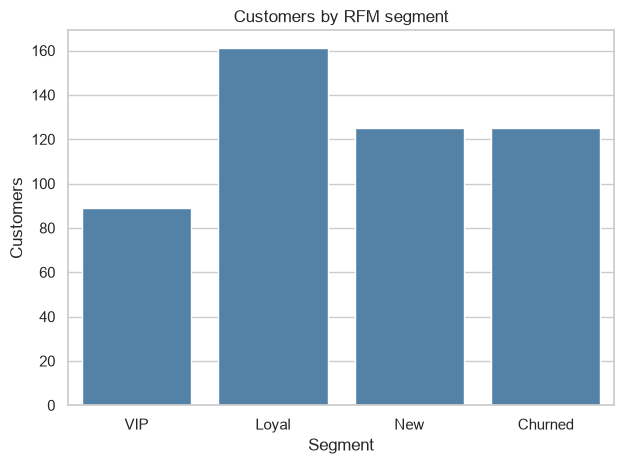

가장 큰 그룹은 **Loyal 161명**이다. VIP는 **89명**으로, 고객 수와 구매금액 비중을 함께 봐야 혜택 대상을 정할 수 있다.

In [14]:
fig, ax = plt.subplots()
sns.barplot(x=segments.index, y=segments["customers"], color="steelblue", ax=ax)
ax.set(title="Customers by RFM segment", xlabel="Segment", ylabel="Customers")
fig.tight_layout()
fig.savefig(figure_dir / "03_segment_barplot.png", dpi=150)
plt.show()
display(Markdown(
    f"가장 큰 그룹은 **{segments.customers.idxmax()} {segments.customers.max()}명**이다. "
    f"VIP는 **{segments.loc['VIP', 'customers']}명**으로, 고객 수와 구매금액 비중을 함께 봐야 혜택 대상을 정할 수 있다."
))

## 8. 결론

VIP에는 유지 혜택을, 관측기간 중 한 번 구매한 New 고객에는 두 번째 주문에 필요한 정보를, Churned에는 재입고 안내를 실험할 수 있다. 구매 이력만으로 실제 가입일이나 이탈을 판정할 수 없으므로 운영 환경에서는 과거 거래와 실험 대조군을 확보해 검증한다.